In [1]:
#imports
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
import IPython.display as ipd

In [ ]:

y,sr=librosa.load(f'../voice_rec.wav')
print('y:', y, '\n')
print('y shape:', np.shape(y), '\n')
print('sample Rate (KHz):', sr, '\n')

y: [ 2.2007634e-05 -2.7910966e-05  3.1030668e-05 ... -5.3287193e-04
 -6.8299426e-04 -4.1674965e-04] 

y shape: (229705,) 

sample Rate (KHz): 22050 



In [10]:
n_fft = 512
hop_len = 128
wind = "hann"

D = librosa.stft(y,n_fft=n_fft,hop_length=hop_len,window=wind)
MG = np.abs(D)
PH = np.angle(D)

In [11]:
MG_db = librosa.amplitude_to_db(MG,ref=np.max)
times = librosa.times_like(D,sr=sr,hop_length=hop_len)
frq = librosa.fft_frequencies(sr=sr,n_fft=n_fft)

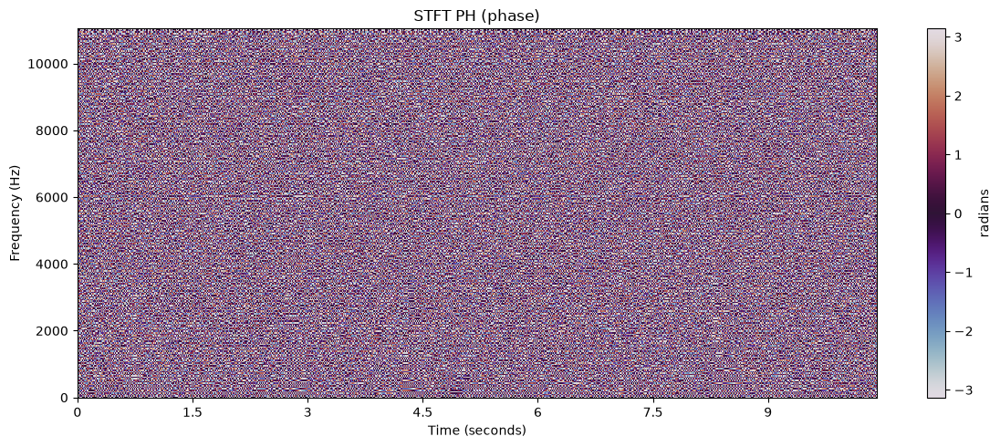

In [12]:
plt.figure(figsize=(12,5))
librosa.display.specshow(
    PH,
    sr=sr,
    hop_length=hop_len,
    x_axis="time",
    y_axis="hz",
    cmap="twilight"
)
plt.colorbar(label="radians")
plt.title("STFT PH (phase)")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.tight_layout()
plt.show()

Noisy so setting low-magnitude region

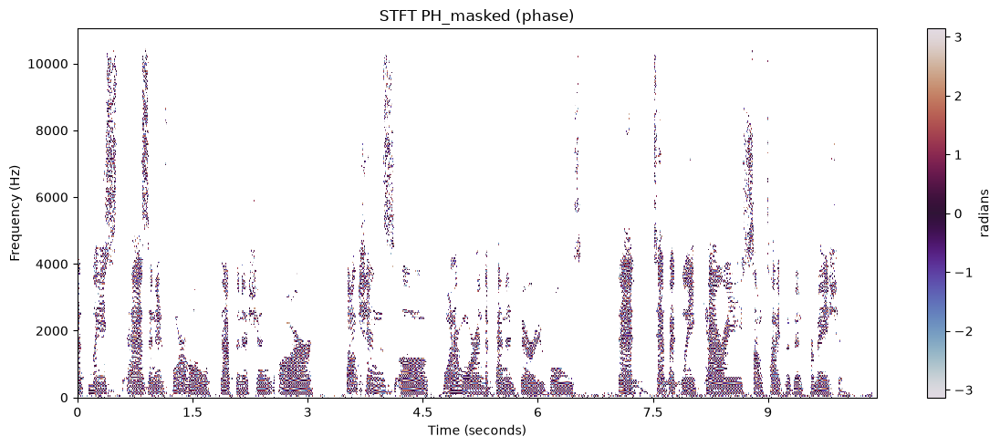

In [13]:
th = -40
PH_Masked = np.ma.masked_where(MG_db<th,PH)
plt.figure(figsize=(12,5))
librosa.display.specshow(
    PH_Masked,
    sr=sr,
    hop_length=hop_len,
    x_axis="time",
    y_axis="hz",
    cmap="twilight",
    vmin=-np.pi,
    vmax=np.pi
)
plt.colorbar(label="radians")
plt.title("STFT PH_masked (phase)")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.tight_layout()
plt.show()


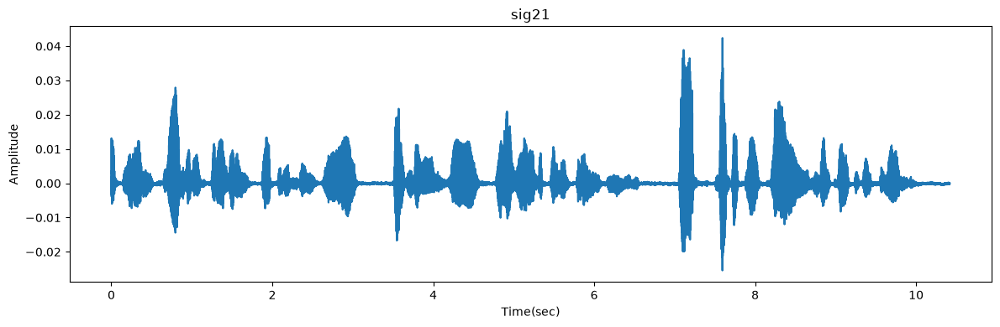

In [15]:
PH11 = np.zeros_like(PH_Masked)

D_sig21 = MG*np.exp(1j*PH11)

sig21 = librosa.istft(D_sig21,hop_length=hop_len,win_length=n_fft,window="hann",length=len(y))
t_sig21=np.arange(len(sig21))/sr

plt.figure(figsize=(12, 4))
plt.plot(t_sig21, sig21)
plt.title("sig21")
plt.xlabel("Time(sec)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()


In [19]:
from pystoi.stoi import stoi
def randnoise(shape,rng):
    ph=rng.uniform(low=-np.pi,high=np.pi,size=shape)
    ph[0,:]=0.0
    ph[-1,:]=0.0
    return ph

rng = np.random.default_rng(0)
ph = randnoise(PH.shape,rng)
D_scram =  MG * np.exp(1j * ph)
sig_scram = librosa.istft(D_scram, hop_length=hop_len, win_length=n_fft, window="hann", length=len(y))

def recover(x, sr, nfft=512, hop=128, n_iter=100, momentum=0.99):
    mag = np.abs(
        librosa.stft(
            x,
            n_fft=nfft,
            hop_length=hop,
            win_length=nfft,
            window="hann"
        )
    )

    rec = librosa.griffinlim(
        mag,
        n_iter=n_iter,
        momentum=momentum,
        hop_length=hop,
        win_length=nfft,
        window="hann",
        length=len(x)
    )

    return rec

sig_rec = recover(
    sig_scram,
    sr,
    nfft=n_fft,
    hop=hop_len,
    n_iter=100
)
min_len = min(len(y), len(sig_scram), len(sig_rec))

y_eval = y[:min_len]
scram_eval = sig_scram[:min_len]
rec_eval = sig_rec[:min_len]

def normalize(x):
    return x / (np.max(np.abs(x)) + 1e-12)

y_eval = normalize(y_eval)
scram_eval = normalize(scram_eval)
rec_eval = normalize(rec_eval)

print("STOI scrambled:", stoi(y_eval, scram_eval, sr))
print("STOI recovered:", stoi(y_eval, rec_eval, sr))
for iterations in [32, 100, 300,1000]:
    sig_rec_test = recover(
        sig_scram,
        sr,
        n_fft,
        hop_len,
        iterations
    )

    test_len = min(len(y), len(sig_rec_test))

    score = stoi(
        normalize(y[:test_len]),
        normalize(sig_rec_test[:test_len]),
        sr
    )

    print(f"Iterations: {iterations}, STOI: {score:.4f}")

STOI scrambled: 0.8607286211877266
STOI recovered: 0.8601961500774904
Iterations: 32, STOI: 0.8593
Iterations: 100, STOI: 0.8607
Iterations: 300, STOI: 0.8606
Iterations: 1000, STOI: 0.8607


In [20]:
import pandas as pd
def si_sdr(ref, est, eps=1e-12):
    ref = ref - ref.mean()
    est = est - est.mean()
    alpha = np.dot(est, ref) / (np.dot(ref, ref) + eps)
    target = alpha * ref
    noise = est - target
    return 10 * np.log10((np.sum(target**2) + eps) / (np.sum(noise**2) + eps))

def gl(mag, n_iter, seed, nfft, hop, length, momentum=0.99):
    return librosa.griffinlim(mag, n_iter=n_iter, momentum=momentum,
                              hop_length=hop, win_length=nfft, window="hann",
                              length=length, random_state=seed)

seeds = [0, 1, 2]
mag_scram = np.abs(librosa.stft(sig_scram, n_fft=n_fft, hop_length=hop_len,
                                win_length=n_fft, window="hann"))

rows = []
for n_iter in [32, 100, 300, 1000]:
    for label, mag in [("realistic (scrambled mag)", mag_scram), ("oracle (true mag)", MG)]:
        st, ss = [], []
        for s in seeds:
            rec = gl(mag, n_iter, s, n_fft, hop_len, len(y))
            st.append(stoi(y, rec, sr))
            ss.append(si_sdr(y, rec))
        rows.append({"method": label, "n_iter": n_iter,
                     "STOI_mean": np.mean(st), "STOI_std": np.std(st),
                     "SISDR_mean": np.mean(ss), "SISDR_std": np.std(ss)})

df_rec = pd.DataFrame(rows)
print(df_rec.round(4).to_string(index=False))


C:\Users\shree\AppData\Local\Temp\ipykernel_4772\4218593183.py:11: FutureWarning: griffinlim() keyword argument 'random_state' has been renamed to 'rng' in version 1.0.0.
	This alias will be removed in version 1.2.0.
  return librosa.griffinlim(mag, n_iter=n_iter, momentum=momentum,


                   method  n_iter  STOI_mean  STOI_std  SISDR_mean  SISDR_std
realistic (scrambled mag)      32     0.8595    0.0008    -30.0019     6.1094
        oracle (true mag)      32     0.9935    0.0006    -28.0841     8.5890
realistic (scrambled mag)     100     0.8605    0.0001    -26.8834     3.8717
        oracle (true mag)     100     0.9976    0.0003    -25.5018     4.9418
realistic (scrambled mag)     300     0.8606    0.0003    -32.3138    11.8696
        oracle (true mag)     300     0.9983    0.0002    -31.2804     2.7634
realistic (scrambled mag)    1000     0.8606    0.0003    -30.8386    10.8527
        oracle (true mag)    1000     0.9985    0.0002    -21.3622     3.0070


scrambled  STOI 0.8607  SI-SDR -23.27 dB
 n_fft       ms   STOI    SISDR
   256  11.6100 0.8475 -41.3780
   512  23.2200 0.8607 -23.2665
  1024  46.4399 0.8436 -27.0426
  2048  92.8798 0.7816 -19.1416
  4096 185.7596 0.6771 -18.3296


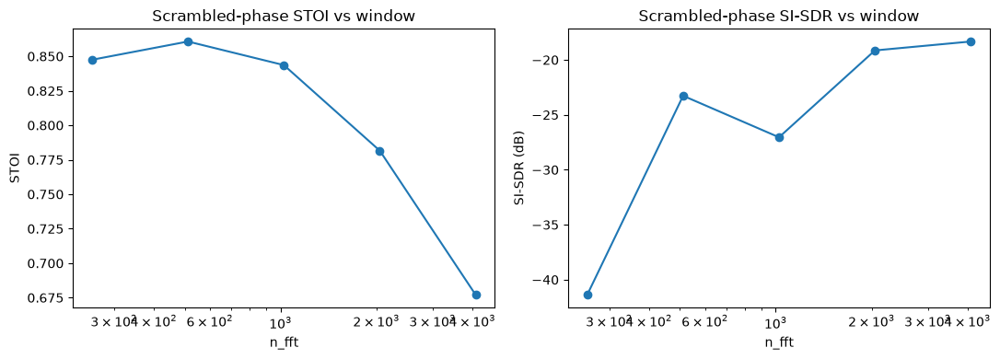

In [23]:

print("scrambled  STOI %.4f  SI-SDR %.2f dB" % (stoi(y, sig_scram, sr), si_sdr(y, sig_scram)))

rows = []
for nf in [256, 512, 1024, 2048, 4096]:
    hp = nf // 4
    D = librosa.stft(y, n_fft=nf, hop_length=hp, win_length=nf, window="hann")
    ph = randnoise(D.shape, np.random.default_rng(0))
    xs = librosa.istft(np.abs(D) * np.exp(1j * ph), hop_length=hp,
                       win_length=nf, window="hann", length=len(y))
    rows.append({"n_fft": nf, "ms": 1000 * nf / sr,
                 "STOI": stoi(y, xs, sr), "SISDR": si_sdr(y, xs)})

df_nfft = pd.DataFrame(rows)
print(df_nfft.round(4).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].semilogx(df_nfft["n_fft"], df_nfft["STOI"], "o-")
ax[0].set_xlabel("n_fft"); ax[0].set_ylabel("STOI"); ax[0].set_title("Scrambled-phase STOI vs window")
ax[1].semilogx(df_nfft["n_fft"], df_nfft["SISDR"], "o-")
ax[1].set_xlabel("n_fft"); ax[1].set_ylabel("SI-SDR (dB)"); ax[1].set_title("Scrambled-phase SI-SDR vs window")
fig.tight_layout()


In [48]:
for hop in [256, 128, 64, 32]:
    D = librosa.stft(y, n_fft=512, hop_length=hop, win_length=512, window="hann")
    mag = np.abs(D)
    rec = librosa.griffinlim(mag, n_iter=300, momentum=0.99, hop_length=hop,
                             win_length=512, window="hann", length=len(y), rng=0)
    print(hop, "STOI %.4f  SI-SDR %.1f dB" % (stoi(y, rec, sr), si_sdr(y, rec)))

256 STOI 0.9632  SI-SDR -25.9 dB
128 STOI 0.9986  SI-SDR -33.2 dB
64 STOI 0.9993  SI-SDR -25.7 dB
32 STOI 0.9995  SI-SDR -12.5 dB


In [27]:
snr_db=[-2,0,2,5,10]
files = {"babble": "../babble.wav", "machinegun": "../machinegun.wav", "white": "../white.wav"}
noisy_signals = {}
def addnoise(clean, noise, snr_db):
    if len(noise) < len(clean):
        noise = np.tile(noise, int(np.ceil(len(clean) / len(noise))))
    noise = noise[:len(clean)]
    clean_power = np.mean(clean**2)
    noise_power = np.mean(noise**2)
    scale = np.sqrt(
        clean_power / (noise_power * 10 ** (snr_db / 10))
    )
    return clean + scale * noise

res = []
for noise_name, noise_file in files.items():
    noise,noise_sr = librosa.load(noise_file,sr=None,mono=True)
    if noise_sr != sr:
        noise = librosa.resample(noise, orig_sr=noise_sr, target_sr=sr)
    for snr in snr_db:
        noisy = addnoise(y, noise, snr)
        noisy_signals[(noise_name, snr)] = noisy
        score = stoi(y, noisy, sr,extended=False)
        res.append({"noise": noise_name, "snr_db": snr, "STOI": score})
        print(f"Noise: {noise_name}, SNR: {snr} dB, STOI: {score:.4f}")


Noise: babble, SNR: -2 dB, STOI: 0.5793
Noise: babble, SNR: 0 dB, STOI: 0.6268
Noise: babble, SNR: 2 dB, STOI: 0.6738
Noise: babble, SNR: 5 dB, STOI: 0.7412
Noise: babble, SNR: 10 dB, STOI: 0.8368
Noise: machinegun, SNR: -2 dB, STOI: 0.7607
Noise: machinegun, SNR: 0 dB, STOI: 0.7892
Noise: machinegun, SNR: 2 dB, STOI: 0.8162
Noise: machinegun, SNR: 5 dB, STOI: 0.8539
Noise: machinegun, SNR: 10 dB, STOI: 0.9085
Noise: white, SNR: -2 dB, STOI: 0.6896
Noise: white, SNR: 0 dB, STOI: 0.7324
Noise: white, SNR: 2 dB, STOI: 0.7725
Noise: white, SNR: 5 dB, STOI: 0.8259
Noise: white, SNR: 10 dB, STOI: 0.8931


In [28]:
from scipy.signal import (butter, cheby1, cheby2, ellip, firwin,
sosfiltfilt, sosfreqz, freqz, fftconvolve)
case = "babble"
x = noisy_signals[(case, 0)]

# Filter definitions
bands = {
    "300-3400": (300, 3400),
    "100-4000": (100, 4000),
    "80-7000": (80, 7000)
}

kinds = [
    "Butterworth",
    "Chebyshev I",
    "Chebyshev II",
    "Elliptic",
    "FIR (Hamming)"
]


def make_filter(kind, lo, hi, sr, order=4, taps=513):
    if kind == "Butterworth":
        return (
            "sos",
            butter(
                order,
                [lo, hi],
                btype="bandpass",
                fs=sr,
                output="sos"
            )
        )

    if kind == "Chebyshev I":
        return (
            "sos",
            cheby1(
                order,
                1,
                [lo, hi],
                btype="bandpass",
                fs=sr,
                output="sos"
            )
        )

    if kind == "Chebyshev II":
        return (
            "sos",
            cheby2(
                order,
                40,
                [lo, hi],
                btype="bandpass",
                fs=sr,
                output="sos"
            )
        )

    if kind == "Elliptic":
        return (
            "sos",
            ellip(
                order,
                1,
                40,
                [lo, hi],
                btype="bandpass",
                fs=sr,
                output="sos"
            )
        )

    return (
        "fir",
        firwin(
            taps,
            [lo, hi],
            pass_zero=False,
            fs=sr
        )
    )


def apply_filter(f, signal):
    filter_type, coefficients = f

    if filter_type == "sos":
        return sosfiltfilt(coefficients, signal)

    return fftconvolve(signal, coefficients, mode="same")


def response_db(f, sr, n=4096):
    filter_type, coefficients = f

    if filter_type == "sos":
        frequency, response = sosfreqz(
            coefficients,
            worN=n,
            fs=sr
        )

        # Zero-phase filtering applies the filter twice
        db = 40 * np.log10(np.abs(response) + 1e-12)

    else:
        frequency, response = freqz(
            coefficients,
            worN=n,
            fs=sr
        )

        db = 20 * np.log10(np.abs(response) + 1e-12)

    return frequency, db


def evaluate_filter(f, clean, noisy_signal, sr):
    # Separate clean and noise components
    noise_signal = noisy_signal - clean

    # Filter each component separately
    filtered_clean = apply_filter(f, clean)
    filtered_noisy = apply_filter(f, noisy_signal)
    filtered_noise = apply_filter(f, noise_signal)

    stoi_vs_clean = stoi(
        clean,
        filtered_noisy,
        sr,
        extended=False
    )

    stoi_vs_filtered_clean = stoi(
        filtered_clean,
        filtered_noisy,
        sr,
        extended=False
    )

    snr_after_db = 10 * np.log10(
        np.mean(filtered_clean ** 2) /
        (np.mean(filtered_noise ** 2) + 1e-12)
    )

    return {
        "STOI_vs_clean": stoi_vs_clean,
        "STOI_vs_filtered_clean": stoi_vs_filtered_clean,
        "SNR_after_dB": snr_after_db
    }


# Create all filters and filtered signals
filters = {
    (kind, band): make_filter(kind, *bands[band], sr)
    for kind in kinds
    for band in bands
}

output1 = {
    key: apply_filter(filter_obj, x)
    for key, filter_obj in filters.items()
}

# Unfiltered baseline
base_stoi = stoi(
    y,
    x,
    sr,
    extended=False
)

base_snr = 10 * np.log10(
    np.mean(y ** 2) /
    (np.mean((x - y) ** 2) + 1e-12)
)

# Evaluate all filters
rows = []

for (kind, band), filter_obj in filters.items():
    metrics = evaluate_filter(
        filter_obj,
        y,
        x,
        sr
    )

    rows.append({
        "filter": kind,
        "band": band,
        **metrics,
        "delta_STOI_vs_clean":
            metrics["STOI_vs_clean"] - base_stoi
    })

res = pd.DataFrame(rows)

print(f"Case: {case}")
print(f"Unfiltered STOI: {base_stoi:.4f}")
print(f"Unfiltered SNR: {base_snr:.2f} dB")
print()
print(res.round(4).to_string(index=False))

print("\nSTOI against original clean signal:")
print(
    res.pivot(
        index="filter",
        columns="band",
        values="STOI_vs_clean"
    ).round(4)
)

print("\nSTOI against filtered clean signal:")
print(
    res.pivot(
        index="filter",
        columns="band",
        values="STOI_vs_filtered_clean"
    ).round(4)
)

print("\nSNR after filtering:")
print(
    res.pivot(
        index="filter",
        columns="band",
        values="SNR_after_dB"
    ).round(2)
)

Case: babble
Unfiltered STOI: 0.6268
Unfiltered SNR: 0.00 dB

       filter     band  STOI_vs_clean  STOI_vs_filtered_clean  SNR_after_dB  delta_STOI_vs_clean
  Butterworth 300-3400         0.6140                  0.6780        1.4279              -0.0128
  Butterworth 100-4000         0.6255                  0.6664        0.0606              -0.0012
  Butterworth  80-7000         0.6268                  0.6581        0.1179               0.0000
  Chebyshev I 300-3400         0.6012                  0.6735        1.2182              -0.0256
  Chebyshev I 100-4000         0.6268                  0.6595        0.0242               0.0000
  Chebyshev I  80-7000         0.6271                  0.6550       -0.0659               0.0003
 Chebyshev II 300-3400         0.5872                  0.7347        1.0839              -0.0396
 Chebyshev II 100-4000         0.6046                  0.6610        0.7391              -0.0222
 Chebyshev II  80-7000         0.6281                  0.6668    

In [33]:
def match_rms(sig, ref):
    return sig * np.sqrt(np.mean(ref ** 2) / (np.mean(sig ** 2) + 1e-12))

In [41]:
from IPython.display import Audio, display
import soundfile as sf
import os
pick_band = "300-3400"
def play(label, sig,pk):
    print(label)
    filename = f"{label}_{pk}hz.wav"
    sf.write(filename,sig, sr)
    display(Audio(np.clip(match_rms(sig, x), -1, 1), rate=sr, normalize=False))

play("clean", y,pick_band)
play("noisy (unfiltered)", x,pick_band)
for k in kinds:
    play(f"{k}, {pick_band}", output1[(k, pick_band)],pick_band)
for b in bands:
    play(f"Butterworth, {b}", output1[("Butterworth", b)],{b})

clean


noisy (unfiltered)


Butterworth, 300-3400


Chebyshev I, 300-3400


Chebyshev II, 300-3400


Elliptic, 300-3400


FIR (Hamming), 300-3400


Butterworth, 300-3400


Butterworth, 100-4000


Butterworth, 80-7000


In [39]:
# Select one noisy test case
case = "white"
x = noisy_signals[(case, 0)]

# Filter definitions
bands = {
    "300-3400": (300, 3400),
    "100-4000": (100, 4000),
    "80-7000": (80, 7000)
}

kinds = [
    "Butterworth",
    "Chebyshev I",
    "Chebyshev II",
    "Elliptic",
    "FIR (Hamming)"
]


def make_filter(kind, lo, hi, sr, order=4, taps=513):
    if kind == "Butterworth":
        return (
            "sos",
            butter(
                order,
                [lo, hi],
                btype="bandpass",
                fs=sr,
                output="sos"
            )
        )

    if kind == "Chebyshev I":
        return (
            "sos",
            cheby1(
                order,
                1,
                [lo, hi],
                btype="bandpass",
                fs=sr,
                output="sos"
            )
        )

    if kind == "Chebyshev II":
        return (
            "sos",
            cheby2(
                order,
                40,
                [lo, hi],
                btype="bandpass",
                fs=sr,
                output="sos"
            )
        )

    if kind == "Elliptic":
        return (
            "sos",
            ellip(
                order,
                1,
                40,
                [lo, hi],
                btype="bandpass",
                fs=sr,
                output="sos"
            )
        )

    return (
        "fir",
        firwin(
            taps,
            [lo, hi],
            pass_zero=False,
            fs=sr
        )
    )


def apply_filter(f, signal):
    filter_type, coefficients = f

    if filter_type == "sos":
        return sosfiltfilt(coefficients, signal)

    return fftconvolve(signal, coefficients, mode="same")


def response_db(f, sr, n=4096):
    filter_type, coefficients = f

    if filter_type == "sos":
        frequency, response = sosfreqz(
            coefficients,
            worN=n,
            fs=sr
        )

        # Zero-phase filtering applies the filter twice
        db = 40 * np.log10(np.abs(response) + 1e-12)

    else:
        frequency, response = freqz(
            coefficients,
            worN=n,
            fs=sr
        )

        db = 20 * np.log10(np.abs(response) + 1e-12)

    return frequency, db


def evaluate_filter(f, clean, noisy_signal, sr):
    # Separate clean and noise components
    noise_signal = noisy_signal - clean

    # Filter each component separately
    filtered_clean = apply_filter(f, clean)
    filtered_noisy = apply_filter(f, noisy_signal)
    filtered_noise = apply_filter(f, noise_signal)

    stoi_vs_clean = stoi(
        clean,
        filtered_noisy,
        sr,
        extended=False
    )

    stoi_vs_filtered_clean = stoi(
        filtered_clean,
        filtered_noisy,
        sr,
        extended=False
    )

    snr_after_db = 10 * np.log10(
        np.mean(filtered_clean ** 2) /
        (np.mean(filtered_noise ** 2) + 1e-12)
    )

    return {
        "STOI_vs_clean": stoi_vs_clean,
        "STOI_vs_filtered_clean": stoi_vs_filtered_clean,
        "SNR_after_dB": snr_after_db
    }


# Create all filters and filtered signals
filters = {
    (kind, band): make_filter(kind, *bands[band], sr)
    for kind in kinds
    for band in bands
}

output2 = {
    key: apply_filter(filter_obj, x)
    for key, filter_obj in filters.items()
}

# Unfiltered baseline
base_stoi = stoi(
    y,
    x,
    sr,
    extended=False
)

base_snr = 10 * np.log10(
    np.mean(y ** 2) /
    (np.mean((x - y) ** 2) + 1e-12)
)

# Evaluate all filters
rows = []

for (kind, band), filter_obj in filters.items():
    metrics = evaluate_filter(
        filter_obj,
        y,
        x,
        sr
    )

    rows.append({
        "filter": kind,
        "band": band,
        **metrics,
        "delta_STOI_vs_clean":
            metrics["STOI_vs_clean"] - base_stoi
    })

res = pd.DataFrame(rows)

print(f"Case: {case}")
print(f"Unfiltered STOI: {base_stoi:.4f}")
print(f"Unfiltered SNR: {base_snr:.2f} dB")
print()
print(res.round(4).to_string(index=False))

print("\nSTOI against original clean signal:")
print(
    res.pivot(
        index="filter",
        columns="band",
        values="STOI_vs_clean"
    ).round(4)
)

print("\nSTOI against filtered clean signal:")
print(
    res.pivot(
        index="filter",
        columns="band",
        values="STOI_vs_filtered_clean"
    ).round(4)
)

print("\nSNR after filtering:")
print(
    res.pivot(
        index="filter",
        columns="band",
        values="SNR_after_dB"
    ).round(2)
)

Case: white
Unfiltered STOI: 0.7324
Unfiltered SNR: -0.00 dB

       filter     band  STOI_vs_clean  STOI_vs_filtered_clean  SNR_after_dB  delta_STOI_vs_clean
  Butterworth 300-3400         0.6832                  0.7824        4.3748              -0.0491
  Butterworth 100-4000         0.7331                  0.7700        4.2408               0.0007
  Butterworth  80-7000         0.7325                  0.7627        1.6760               0.0001
  Chebyshev I 300-3400         0.6621                  0.7825        4.1493              -0.0703
  Chebyshev I 100-4000         0.7323                  0.7650        3.5273              -0.0001
  Chebyshev I  80-7000         0.7316                  0.7607        0.9759              -0.0007
 Chebyshev II 300-3400         0.6240                  0.7997        3.8835              -0.1084
 Chebyshev II 100-4000         0.6863                  0.7667        6.3183              -0.0460
 Chebyshev II  80-7000         0.7161                  0.7672    

In [47]:
def play1(label, sig):
    print(label)
    display(Audio(np.clip(match_rms(sig, x), -1, 1), rate=sr, normalize=False))

play1("clean", y)
play1("noisy (unfiltered)", x)
for k in kinds:
    play1(f"{k}, {pick_band}", output2[(k, pick_band)])
for b in bands:
    play1(f"Butterworth, {b}", output2[("Butterworth", b)])

clean


noisy (unfiltered)


Butterworth, 300-3400


Chebyshev I, 300-3400


Chebyshev II, 300-3400


Elliptic, 300-3400


FIR (Hamming), 300-3400


Butterworth, 300-3400


Butterworth, 100-4000


Butterworth, 80-7000


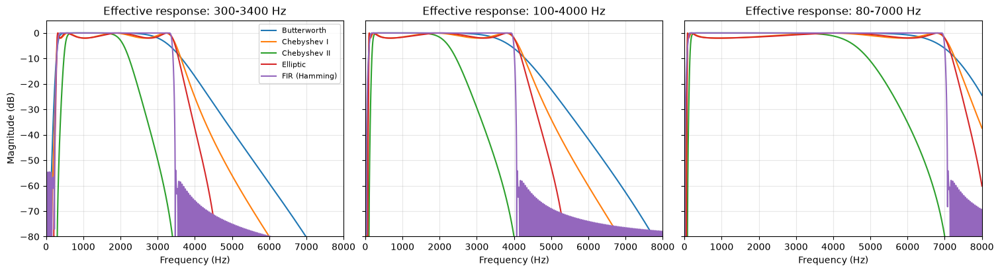

In [43]:
fig, axes = plt.subplots(
    1,
    len(bands),
    figsize=(15, 4),
    sharey=True,
    constrained_layout=True
)

axes = np.atleast_1d(axes)

for ax, band in zip(axes, bands):
    for kind in kinds:
        frequency, db = response_db(
            filters[(kind, band)],
            sr
        )

        ax.plot(
            frequency,
            db,
            label=kind
        )

    ax.set_xlim(0, 8000)
    ax.set_ylim(-80, 5)
    ax.set_title(f"Effective response: {band} Hz")
    ax.set_xlabel("Frequency (Hz)")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Magnitude (dB)")
axes[0].legend(fontsize=8)

plt.show()

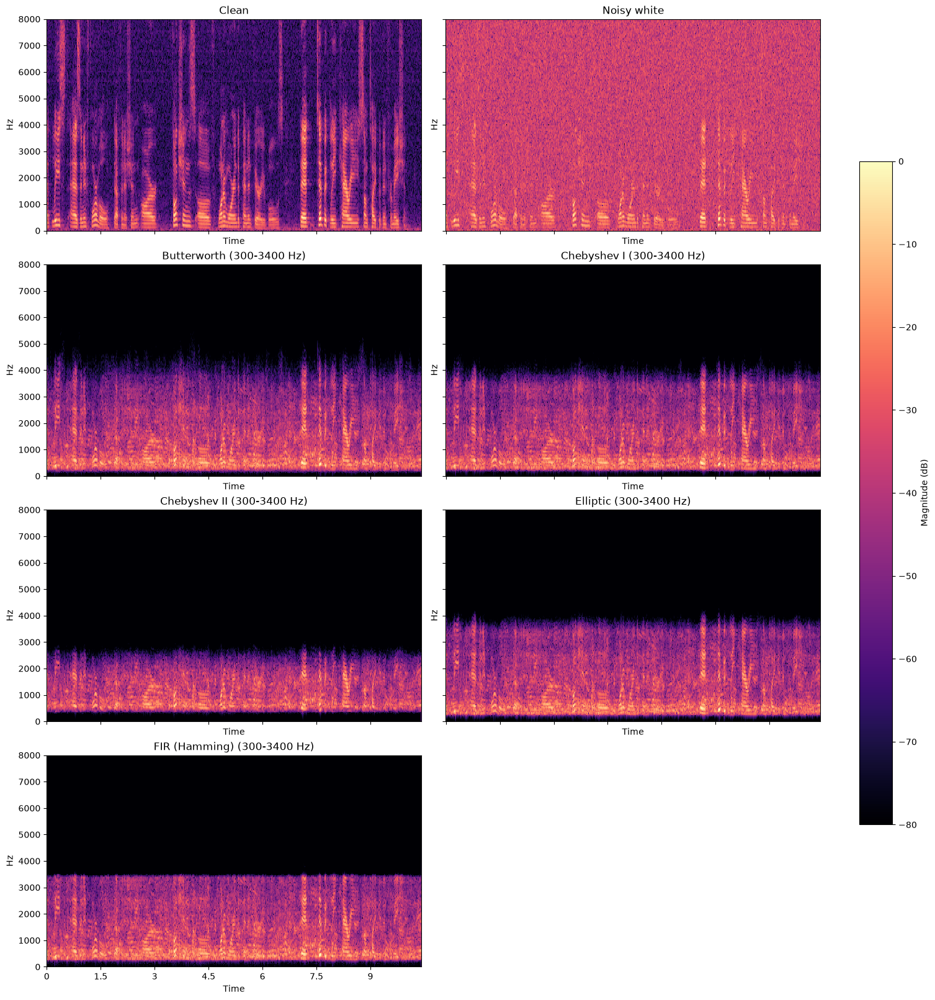

In [45]:
pick_band = "300-3400"

panels = [
    ("Clean", y),
    (f"Noisy {case}", x)
]

panels += [
    (kind, output1[(kind, pick_band)])
    for kind in kinds
]

fig, axes = plt.subplots(
    4,
    2,
    figsize=(15, 16),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

axes = axes.ravel()

# Use one common reference for all spectrograms
clean_stft = librosa.stft(
    y,
    n_fft=n_fft,
    hop_length=hop_len
)

reference = np.max(np.abs(clean_stft))

for ax, (title, signal) in zip(axes, panels):
    signal_stft = librosa.stft(
        signal,
        n_fft=n_fft,
        hop_length=hop_len
    )

    signal_db = librosa.amplitude_to_db(
        np.abs(signal_stft),
        ref=reference
    )

    image = librosa.display.specshow(
        signal_db,
        sr=sr,
        hop_length=hop_len,
        x_axis="time",
        y_axis="hz",
        vmin=-80,
        vmax=0,
        ax=ax
    )

    ax.set_ylim(0, 8000)
    ax.set_title(
        title if title in ["Clean", f"Noisy {case}"]
        else f"{title} ({pick_band} Hz)"
    )

# Hide unused subplot
for ax in axes[len(panels):]:
    ax.axis("off")

fig.colorbar(
    image,
    ax=axes.tolist(),
    label="Magnitude (dB)",
    shrink=0.7
)
plt.show()

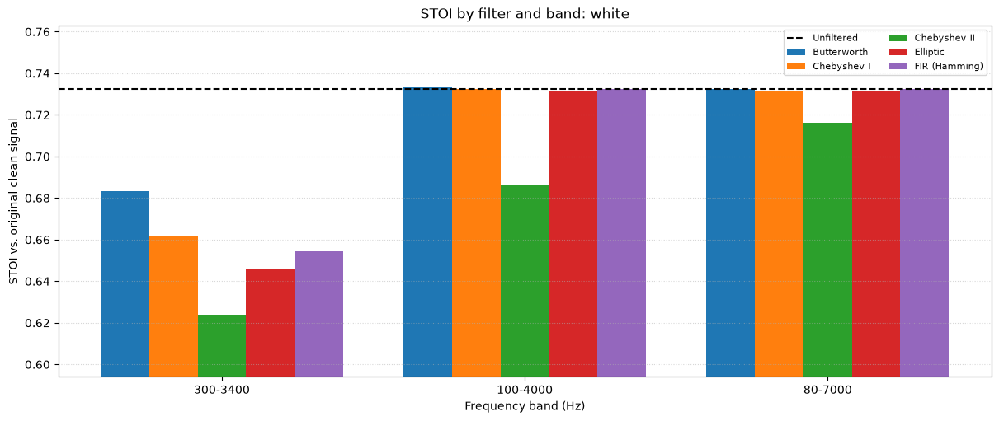

In [46]:
fig, ax = plt.subplots(
    figsize=(12, 5),
    constrained_layout=True
)

x_positions = np.arange(len(bands))
bar_width = 0.8 / len(kinds)

for i, kind in enumerate(kinds):
    values = [
        res.loc[
            (res["filter"] == kind) &
            (res["band"] == band),
            "STOI_vs_clean"
        ].iloc[0]
        for band in bands
    ]

    ax.bar(
        x_positions + i * bar_width,
        values,
        width=bar_width,
        label=kind
    )

ax.axhline(
    base_stoi,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Unfiltered"
)

ax.set_xticks(
    x_positions +
    (len(kinds) - 1) * bar_width / 2
)

ax.set_xticklabels(list(bands))
ax.set_xlabel("Frequency band (Hz)")
ax.set_ylabel("STOI vs. original clean signal")
ax.set_title(f"STOI by filter and band: {case}")
ax.set_ylim(
    min(res["STOI_vs_clean"].min(), base_stoi) - 0.03,
    max(res["STOI_vs_clean"].max(), base_stoi) + 0.03
)

ax.legend(
    fontsize=8,
    ncol=2
)

ax.grid(
    axis="y",
    linestyle=":",
    alpha=0.5
)

plt.show()